<a href="https://colab.research.google.com/github/EmiiFernandez/actividades_data_sciente_ypf/blob/main/notebook/C25_Notebook-29.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

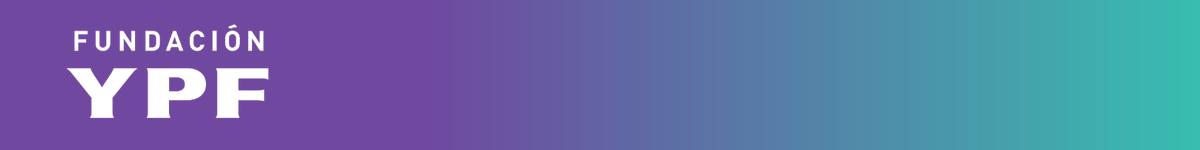

# Fundación YPF - Data Science

## Notebook 29: Introducción a redes neuronales. Perceptrón simple

### Índice de partes

* **Parte 0:** Preparación del entorno
* **Parte 1:** Repaso: de los clusters a los datos etiquetados
* **Parte 2:** El perceptrón simple paso a paso, con numpy
* **Parte 3:** El perceptrón con scikit-learn
* **Parte 4:** Aplicación a datos reales: cáncer de mama
* **Parte 5:** Ejercicio para las salas de Zoom

## Parte 0: Preparación del entorno

Hasta la clase anterior trabajamos con **aprendizaje NO supervisado** (clustering: K-Means y DBSCAN). Hoy arrancamos un módulo nuevo: **redes neuronales**, empezando por la unidad más simple, el **perceptrón**. El perceptrón es un modelo de **aprendizaje supervisado**: necesita datos con etiqueta (la clase correcta de cada ejemplo) para poder entrenarse.

En esta notebook vamos a:

* repasar brevemente la diferencia entre no tener etiquetas (clustering) y sí tenerlas (clasificación),
* implementar un perceptrón simple **a mano, con numpy**, para entender pesos, sesgo, función de activación y la actualización por error,
* entrenar el mismo modelo con `Perceptron` de scikit-learn,
* aplicar el perceptrón a un problema real de clasificación binaria.

**Datasets:**

* En las Partes 1 a 3 generamos datos sintéticos con scikit-learn (`make_blobs`): no hace falta ningún archivo.
* `cancer_mamario.csv`: datos de pacientes con cáncer de mama, con una columna `class` que indica si hubo o no recurrencia de la enfermedad. Es el mismo dataset que usamos en las clases de clasificación clásica (árboles, regresión logística). Lo usamos en la Parte 4.
* `StudentsPerformance.csv`: datos de 1000 estudiantes (el mismo de otras clases). Lo usamos en el ejercicio de las salas (Parte 5).

Antes de ejecutar, subí los archivos `cancer_mamario.csv` y `StudentsPerformance.csv` al panel de archivos de Colab (ícono de carpeta a la izquierda).

In [33]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## Parte 1: Repaso: de los clusters a los datos etiquetados

Generamos un conjunto de datos sintético con dos grupos bien separados y **sus etiquetas reales** (0 y 1). Primero lo tratamos como si no tuviéramos esas etiquetas, igual que en las clases de clustering, y después mostramos las etiquetas verdaderas.

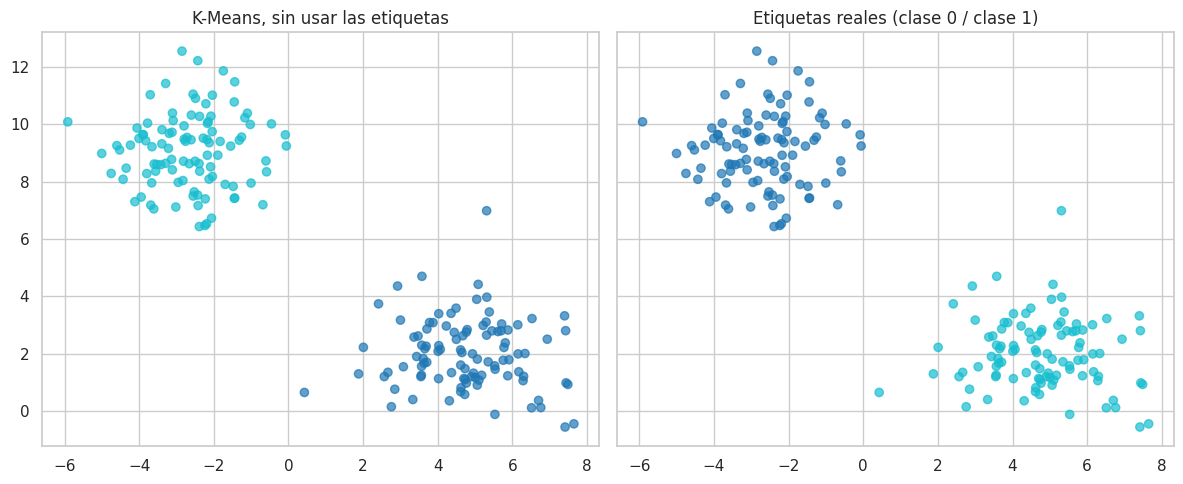

Etiqueta real      0    1
Cluster K-Means          
0                  0  100
1                100    0


In [34]:
X, y = make_blobs(n_samples=200, centers=2, cluster_std=1.3, random_state=RANDOM_STATE)

kmeans_repaso = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE).fit_predict(X)

fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
ax[0].scatter(X[:, 0], X[:, 1], c=kmeans_repaso, cmap="tab10", alpha=0.7)
ax[0].set_title("K-Means, sin usar las etiquetas")
ax[1].scatter(X[:, 0], X[:, 1], c=y, cmap="tab10", alpha=0.7)
ax[1].set_title("Etiquetas reales (clase 0 / clase 1)")
plt.tight_layout()
plt.show()

print(pd.crosstab(kmeans_repaso, y, rownames=["Cluster K-Means"], colnames=["Etiqueta real"]))

K-Means encuentra los dos grupos sin mirar nunca la etiqueta: los separa solo por cercanía entre puntos. Hoy el problema es distinto: **sí tenemos la etiqueta de cada punto**, y el objetivo no es descubrir grupos sino **entrenar un modelo que prediga esa etiqueta** para datos nuevos. Ese es el salto de hoy: pasamos de aprendizaje NO supervisado a aprendizaje **supervisado**, con el primer modelo de una red neuronal, el **perceptrón simple**.

## Parte 2: El perceptrón simple paso a paso, con numpy

Como vimos en la teoría, el perceptrón combina las entradas con sus pesos y un sesgo (bias), y pasa ese resultado por una función de activación:

* **z** = b + w1 * x1 + w2 * x2 (b es el sesgo, lo que en las slides llamamos w0)
* **activación:** acá usamos la función escalón: devuelve 1 si z es mayor o igual a 0, y 0 si es menor.

El entrenamiento es la regla clásica del perceptrón (Rosenblatt):

1. Se calcula la predicción de un ejemplo.
2. Se compara con la etiqueta real y se obtiene el error (real menos predicho).
3. Se actualizan los pesos y el sesgo en la dirección que reduce ese error, multiplicados por la **tasa de aprendizaje**: cuánto se mueve cada peso en cada actualización.
4. Se repite para todos los ejemplos, varias veces (épocas), hasta que el modelo deja de equivocarse o se llega al número máximo de épocas.

In [35]:
Xs = StandardScaler().fit_transform(X)


def activacion_escalon(z):
    return np.where(z >= 0, 1, 0)


def entrenar_perceptron(X, y, tasa_aprendizaje=0.1, epocas=20):
    n_muestras, n_features = X.shape
    w = np.zeros(n_features)
    b = 0.0
    errores_por_epoca = []
    for _ in range(epocas):
        errores = 0
        for xi, yi in zip(X, y):
            z = np.dot(xi, w) + b
            y_pred = activacion_escalon(z)
            error = yi - y_pred
            w = w + tasa_aprendizaje * error * xi
            b = b + tasa_aprendizaje * error
            errores += int(error != 0)
        errores_por_epoca.append(errores)
    return w, b, errores_por_epoca


w, b, errores_por_epoca = entrenar_perceptron(Xs, y, tasa_aprendizaje=0.1, epocas=20)
print("Errores por época:", errores_por_epoca)
print("Pesos finales (w1, w2):", w)
print("Sesgo final (b):", b)

Errores por época: [2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Pesos finales (w1, w2): [ 0.17411676 -0.14094979]
Sesgo final (b): 0.0


La cantidad de errores por época baja hasta llegar a 0: el perceptrón **converge**, porque estos dos grupos son **linealmente separables** (se pueden separar con una línea recta). Cuando no lo son, el perceptrón simple nunca deja de cometer errores, por muchas épocas que le demos. Grafiquemos la frontera de decisión que encontró.

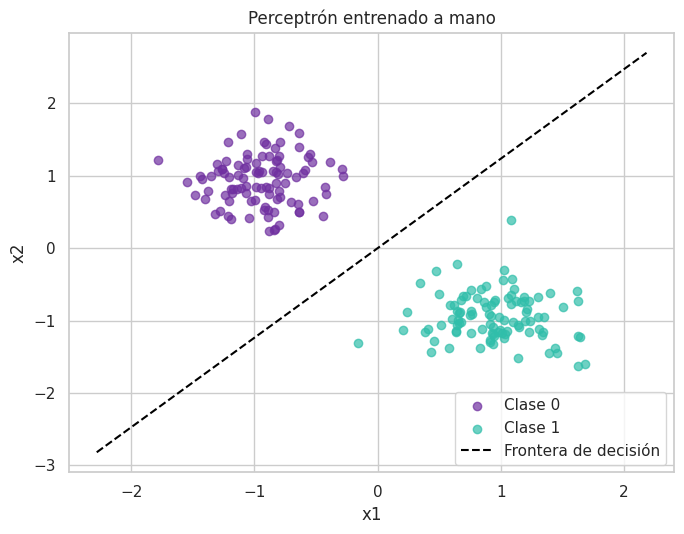

Exactitud del perceptrón manual: 1.0


In [36]:
def graficar_frontera(X, y, w, b, titulo):
    plt.figure(figsize=(7, 5.5))
    plt.scatter(X[y == 0, 0], X[y == 0, 1], color="#7030A0", label="Clase 0", alpha=0.7)
    plt.scatter(X[y == 1, 0], X[y == 1, 1], color="#30BEAA", label="Clase 1", alpha=0.7)
    x1_vals = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 100)
    x2_vals = -(b + w[0] * x1_vals) / w[1]
    plt.plot(x1_vals, x2_vals, color="black", linestyle="--", label="Frontera de decisión")
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(titulo)
    plt.legend()
    plt.tight_layout()
    plt.show()


graficar_frontera(Xs, y, w, b, "Perceptrón entrenado a mano")

y_pred_manual = activacion_escalon(np.dot(Xs, w) + b)
print("Exactitud del perceptrón manual:", accuracy_score(y, y_pred_manual))

## Parte 3: El perceptrón con scikit-learn

Entrenamos ahora `Perceptron` de scikit-learn sobre los mismos datos, para comparar contra la implementación a mano.

In [37]:
perceptron_sk = Perceptron(max_iter=1000, random_state=RANDOM_STATE)
perceptron_sk.fit(Xs, y)

print("Pesos (coef_):", perceptron_sk.coef_)
print("Sesgo (intercept_):", perceptron_sk.intercept_)
print("Exactitud del perceptrón de scikit-learn:", accuracy_score(y, perceptron_sk.predict(Xs)))

Pesos (coef_): [[ 2.19747965 -0.44170983]]
Sesgo (intercept_): [0.]
Exactitud del perceptrón de scikit-learn: 1.0


Los pesos no son idénticos a los de la versión manual (scikit-learn recorre los datos en otro orden y usa su propia implementación internamente), pero ambos llegan a una frontera que separa perfectamente los dos grupos. Confirma que entendimos bien el algoritmo: la diferencia entre "hacerlo a mano" y "usar la librería" está en la comodidad, no en la idea.

## Parte 4: Aplicación a datos reales: cáncer de mama

Los datos sintéticos siempre se pueden separar con una línea si los generamos para eso. Veamos qué pasa con un problema real: `cancer_mamario.csv`, donde la columna `class` indica si la paciente tuvo o no una recurrencia de la enfermedad. Es un problema de **clasificación binaria**.

In [38]:
# Carga del dataset
url = "https://raw.githubusercontent.com/EmiiFernandez/actividades_data_sciente_ypf/main/dataset/"


In [39]:
dataset_cancer = "cancer_mamario.csv"
df_cancer = pd.read_csv(url+dataset_cancer)

cancer = df_cancer.copy()
print("Forma del dataset:", cancer.shape)
cancer.head()

Forma del dataset: (286, 10)


,class,age,menopause,tumor-size,inv-nodes,node-caps,deg-malig,breast,breast-quad,irradiat
0,no-recurrence-events,30-39,premeno,30-34,0-2,no,3,left,left_low,no
1,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,right,right_up,no
2,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,left,left_low,no
3,no-recurrence-events,60-69,ge40,15-19,0-2,no,2,right,left_up,no
4,no-recurrence-events,40-49,premeno,0-4,0-2,no,2,right,right_low,no


Casi todas las columnas son **categóricas** (texto), salvo `deg-malig`. Un perceptrón necesita números, así que hay que codificarlas:

* `age`, `tumor-size` e `inv-nodes` son categorías **con orden** (rangos), así que las convertimos en números que respeten ese orden.
* El resto de las columnas categóricas no tienen orden, así que las codificamos con **one-hot** (una columna binaria por categoría).
* Algunas columnas tienen el valor `"?"` para marcar datos faltantes: los reemplazamos por la categoría más frecuente de esa columna.

In [40]:
cancer_prep = cancer.replace("?", np.nan)

y_cancer = (cancer_prep["class"] == "recurrence-events").astype(int)
X_cancer = cancer_prep.drop(columns="class")

for columna in ["node-caps", "breast-quad"]:
    X_cancer[columna] = X_cancer[columna].fillna(X_cancer[columna].mode()[0])

orden_edad = ["20-29", "30-39", "40-49", "50-59", "60-69", "70-79"]
orden_tumor = ["0-4", "5-9", "10-14", "15-19", "20-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54"]
orden_ganglios = ["0-2", "3-5", "6-8", "9-11", "12-14", "15-17", "18-20", "21-23", "24-26"]

X_cancer["age"] = X_cancer["age"].map({valor: i for i, valor in enumerate(orden_edad)})
X_cancer["tumor-size"] = X_cancer["tumor-size"].map({valor: i for i, valor in enumerate(orden_tumor)})
X_cancer["inv-nodes"] = X_cancer["inv-nodes"].map({valor: i for i, valor in enumerate(orden_ganglios)})

columnas_nominales = ["menopause", "node-caps", "breast", "breast-quad", "irradiat"]
X_cancer = pd.get_dummies(X_cancer, columns=columnas_nominales, drop_first=True)

print("Forma final de X:", X_cancer.shape)
print("Proporción de recurrencias:", round(y_cancer.mean(), 3))
print("Exactitud de un modelo que siempre dice 'no hay recurrencia':", round(1 - y_cancer.mean(), 3))

Forma final de X: (286, 13)
Proporción de recurrencias: 0.297
Exactitud de un modelo que siempre dice 'no hay recurrencia': 0.703


In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X_cancer, y_cancer, test_size=0.25, stratify=y_cancer, random_state=RANDOM_STATE
)

escalador = StandardScaler()
X_train_s = escalador.fit_transform(X_train)
X_test_s = escalador.transform(X_test)

perceptron_cancer = Perceptron(max_iter=1000, random_state=RANDOM_STATE)
perceptron_cancer.fit(X_train_s, y_train)
y_pred_cancer = perceptron_cancer.predict(X_test_s)

print("Exactitud en test:", round(accuracy_score(y_test, y_pred_cancer), 3))
print()
print("Matriz de confusión:")
print(confusion_matrix(y_test, y_pred_cancer))
print()
print(classification_report(y_test, y_pred_cancer, target_names=["no recurrencia", "recurrencia"]))

Exactitud en test: 0.625

Matriz de confusión:
[[38 13]
 [14  7]]

                precision    recall  f1-score   support

no recurrencia       0.73      0.75      0.74        51
   recurrencia       0.35      0.33      0.34        21

      accuracy                           0.62        72
     macro avg       0.54      0.54      0.54        72
  weighted avg       0.62      0.62      0.62        72



A diferencia de los datos sintéticos, acá el perceptrón **no separa perfectamente** las dos clases, y en muchas particiones ni siquiera supera a la exactitud del modelo que siempre dice "no hay recurrencia". Esto no es un error del código: es una limitación real del perceptrón simple, que solo puede trazar una **frontera lineal**. Ya en las clases de clasificación clásica habíamos visto que este dataset es difícil y que varios modelos apenas superan ese piso. La diferencia la va a marcar la próxima clase, cuando agreguemos **más de una capa** al perceptrón (perceptrón multicapa) para poder representar fronteras no lineales.

## Parte 5: Ejercicio para las salas de Zoom

**Dataset:** `StudentsPerformance.csv`. Son 1000 estudiantes con sus datos personales y familiares (género, grupo, nivel educativo de los padres, tipo de almuerzo, si hicieron un curso de preparación) y sus puntajes en tres exámenes.

**Problema:** clasificación binaria. Definan si el estudiante **aprobó o no**, a partir de **datos personales y familiares únicamente** (no de los puntajes, porque usar el puntaje para predecir el puntaje no tiene sentido).

**Tiempo:** 40 minutos. Al final, cada sala comparte sus conclusiones.

**Consigna:**

1. **Variable objetivo.** Calculen el promedio de los tres puntajes y definan `aprobado` como 1 si el promedio es mayor o igual a 60, y 0 si no.
2. **Variables.** Arme `X` con las columnas `gender`, `race/ethnicity`, `parental level of education`, `lunch` y `test preparation course`, codificadas con one-hot (`pd.get_dummies`).
3. **Separación.** Divida en entrenamiento (75%) y test (25%), con `stratify` sobre `aprobado`.
4. **Entrenamiento.** Escale las variables y entrenen un `Perceptron` de scikit-learn.
5. **Evaluación.** Calculen la exactitud en test, compárenla con el piso (el porcentaje de la clase mayoritaria) y miren la matriz de confusión.

**Preguntas para la puesta en común:**

* ¿El perceptrón superó al piso? ¿Por cuánto?
* ¿Cuáles de las variables disponibles les parece que más influyen en aprobar o no?
* Con los datos disponibles (sin los puntajes), ¿les parece razonable que un modelo lineal simple alcance una exactitud alta? ¿Por qué?

In [42]:
# Cargamos el dataset del ejercicio
dataset_students = "StudentsPerformance.csv"
df_students = pd.read_csv(url+dataset_students)

estudiantes = df_students.copy()
print("Forma del dataset:", estudiantes.shape)

estudiantes.head()

Forma del dataset: (1000, 9)


,Unnamed: 0,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,0,female,group B,bachelor's degree,standard,none,7.2,72,74
1,1,female,group C,some college,standard,completed,6.9,90,88
2,2,female,group B,master's degree,standard,none,9.0,95,93
3,3,male,group A,associate's degree,free/reduced,none,4.7,57,44
4,4,male,group C,some college,standard,none,7.6,78,75


In [43]:
if 'Unnamed: 0' in estudiantes.columns:
    estudiantes = estudiantes.drop(columns=['Unnamed: 0'])

# Nombres de columnas más cómodos de escribir
estudiantes.columns = (estudiantes.columns
                    .str.strip()
                    .str.lower()
                    .str.replace(' ', '_')
                    .str.replace('/', '_'))
estudiantes.columns.tolist()

['gender',
 'race_ethnicity',
 'parental_level_of_education',
 'lunch',
 'test_preparation_course',
 'math_score',
 'reading_score',
 'writing_score']

In [44]:

# Encoding de las variables categóricas (clase 7)
categoricas = ['gender', 'race_ethnicity', 'parental_level_of_education',
               'lunch', 'test_preparation_course']

estudiantes_enc = pd.get_dummies(estudiantes, columns=categoricas, drop_first=True)
print('Antes:', estudiantes.shape, ' Después:', estudiantes_enc.shape)
estudiantes_enc.head(3)

Antes: (1000, 8)  Después: (1000, 15)


,math_score,reading_score,writing_score,gender_male,race_ethnicity_group B,race_ethnicity_group C,race_ethnicity_group D,race_ethnicity_group E,parental_level_of_education_bachelor's degree,parental_level_of_education_high school,parental_level_of_education_master's degree,parental_level_of_education_some college,parental_level_of_education_some high school,lunch_standard,test_preparation_course_none
0,7.2,72,74,False,True,False,False,False,True,False,False,False,False,True,True
1,6.9,90,88,False,False,True,False,False,False,False,False,True,False,True,False
2,9.0,95,93,False,True,False,False,False,False,False,True,False,False,True,True


In [45]:
# 1. Variable objetivo: aprobado (promedio de los tres puntajes >= 60)
UMBRAL = 60
puntajes = ['math_score', 'reading_score', 'writing_score']
estudiantes_enc['promedio'] = estudiantes_enc[puntajes].mean(axis=1)
estudiantes_enc['aprobado'] = (estudiantes_enc['promedio'] >= UMBRAL).astype(int)

print(estudiantes_enc['aprobado'].value_counts())

aprobado
0    882
1    118
Name: count, dtype: int64


In [46]:
# 2. Armar X con las variables personales y familiares, codificadas con one-hot
X = estudiantes_enc.drop(columns=puntajes + ['promedio', 'aprobado'])
y = estudiantes_enc['aprobado']

print('Variables de entrada:', X.shape[1])
print(X.columns.tolist())

Variables de entrada: 12
['gender_male', 'race_ethnicity_group B', 'race_ethnicity_group C', 'race_ethnicity_group D', 'race_ethnicity_group E', "parental_level_of_education_bachelor's degree", 'parental_level_of_education_high school', "parental_level_of_education_master's degree", 'parental_level_of_education_some college', 'parental_level_of_education_some high school', 'lunch_standard', 'test_preparation_course_none']


In [47]:
# 3. Separar en entrenamiento y test, con stratify
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y      # mantiene la misma proporción de aprobadas en ambos conjuntos
)

print(f'Entrenamiento: {X_train.shape[0]} estudiantes')
print(f'Test:          {X_test.shape[0]} estudiantes')
print(f'Proporción que aprueba en train: {y_train.mean():.1%}')
print(f'Proporción que aprueba en test:  {y_test.mean():.1%}')

Entrenamiento: 750 estudiantes
Test:          250 estudiantes
Proporción que aprueba en train: 11.9%
Proporción que aprueba en test:  11.6%


In [48]:
# 4. Escalar y entrenar el Perceptron
scaler = StandardScaler()
X_train_est = scaler.fit_transform(X_train)
X_test_est = scaler.transform(X_test)

perceptron_estudiantes = Perceptron(max_iter=1000, random_state=RANDOM_STATE)
perceptron_estudiantes.fit(X_train_est, y_train)
y_pred_estudiantes = perceptron_estudiantes.predict(X_test_est)



In [50]:
# 5. Evaluar: exactitud, piso y matriz de confusión
exactitud = accuracy_score(y_test, y_pred_estudiantes)
piso = y_test.value_counts(normalize=True).max()

print(f"Exactitud en test: {exactitud:.3f}")
print(f"Piso (clase mayoritaria): {piso:.3f}")
print(f"Diferencia: {exactitud - piso:+.3f}")
print()
print("Matriz de confusión (0 = no aprueba, 1 = aprueba):")
print(confusion_matrix(y_test, y_pred_estudiantes))
print()
print(classification_report(y_test, y_pred_estudiantes,
                            target_names=["no aprueba", "aprueba"]))

Exactitud en test: 0.780
Piso (clase mayoritaria): 0.884
Diferencia: -0.104

Matriz de confusión (0 = no aprueba, 1 = aprueba):
[[179  42]
 [ 13  16]]

              precision    recall  f1-score   support

  no aprueba       0.93      0.81      0.87       221
     aprueba       0.28      0.55      0.37        29

    accuracy                           0.78       250
   macro avg       0.60      0.68      0.62       250
weighted avg       0.86      0.78      0.81       250

